# Crop Yield Prediction Project

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

print("Libraries imported successfully!")

Libraries imported successfully!


In [13]:
df = pd.read_csv('crop-yield.csv')

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset Shape: 10000 rows, 20 columns


,N,P,K,Soil_pH,Soil_Moisture,Soil_Type,Organic_Carbon,Temperature,Humidity,Rainfall,Sunlight_Hours,Wind_Speed,Region,Altitude,Season,Crop_Type,Irrigation_Type,Fertilizer_Used,Pesticide_Used,Crop_Yield_ton_per_hectare
0,132,62,22,6.35,59.78,Clay,0.43,22.97,53.89,1305.68,7.73,15.96,Central,36,Rabi,Maize,Canal,223.48,23.36,11.42
1,122,71,66,5.98,25.54,Sandy,0.65,17.00,76.90,1942.05,9.25,12.60,North,1561,Rabi,Potato,Canal,161.54,4.42,23.19
2,44,35,104,8.07,25.87,Sandy,0.79,25.52,44.78,2216.20,8.50,15.63,North,1870,Rabi,Rice,Rainfed,184.62,6.29,7.94
3,136,96,113,4.83,42.97,Silt,0.45,18.59,31.89,607.18,8.75,5.49,East,765,Kharif,Sugarcane,Rainfed,274.02,2.72,72.53
4,101,34,42,5.84,48.01,Silt,0.69,22.74,46.27,483.47,8.00,7.44,Central,1143,Zaid,Wheat,Rainfed,72.69,15.37,6.72


In [15]:
print("--- Dataset Info ---")
df.info()

print("\n--- Missing Values per Column ---")
print(df.isnull().sum())

print(f"\n--- Duplicate Rows: {df.duplicated().sum()} ---")

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   N                           10000 non-null  int64  
 1   P                           10000 non-null  int64  
 2   K                           10000 non-null  int64  
 3   Soil_pH                     10000 non-null  float64
 4   Soil_Moisture               10000 non-null  float64
 5   Soil_Type                   10000 non-null  object 
 6   Organic_Carbon              10000 non-null  float64
 7   Temperature                 10000 non-null  float64
 8   Humidity                    10000 non-null  float64
 9   Rainfall                    10000 non-null  float64
 10  Sunlight_Hours              10000 non-null  float64
 11  Wind_Speed                  10000 non-null  float64
 12  Region                      10000 non-null  object 
 13  Altitude   

In [17]:
print("--- Numeric Summary ---")
display(df.describe().T)

print("\n--- Categorical Summary ---")
display(df.describe(include='object').T)

--- Numeric Summary ---


,count,mean,std,min,25%,50%,75%,max
N,10000.0,104.983000,43.291654,30.00,68.0000,105.00,142.0000,179.00
P,10000.0,56.809600,24.522962,15.00,35.0000,57.00,78.0000,99.00
K,10000.0,85.008700,37.541443,20.00,52.0000,85.00,118.0000,149.00
Soil_pH,10000.0,6.504306,0.978698,4.80,5.6700,6.52,7.3500,8.20
Soil_Moisture,10000.0,40.083748,14.461944,15.00,27.6300,40.00,52.7625,64.99
Organic_Carbon,10000.0,0.958356,0.375027,0.30,0.6300,0.96,1.2900,1.60
Temperature,10000.0,25.097402,8.719031,10.00,17.5900,24.97,32.8300,40.00
Humidity,10000.0,59.894209,17.402450,30.01,44.8300,59.55,75.0375,89.99
Rainfall,10000.0,1546.694887,718.865960,300.70,925.7675,1548.55,2165.4525,2799.26
Sunlight_Hours,10000.0,7.507868,2.006472,4.00,5.7700,7.53,9.2200,11.00



--- Categorical Summary ---


,count,unique,top,freq
Soil_Type,10000,4,Loamy,2543
Region,10000,5,South,2013
Season,10000,3,Rabi,3355
Crop_Type,10000,6,Rice,1702
Irrigation_Type,10000,4,Drip,2532


,count,mean,std,min,median,max
Crop_Type,,,,,,
Sugarcane,1633,74.830257,1.637562,69.69,74.830,80.99
Potato,1670,24.891012,1.681934,20.32,24.830,30.27
Maize,1658,10.076037,1.701917,5.48,10.050,15.60
Rice,1702,9.402027,1.657081,4.07,9.425,14.20
Wheat,1671,8.724680,1.649251,3.78,8.740,14.09
Cotton,1666,7.427941,1.727750,1.76,7.420,12.86


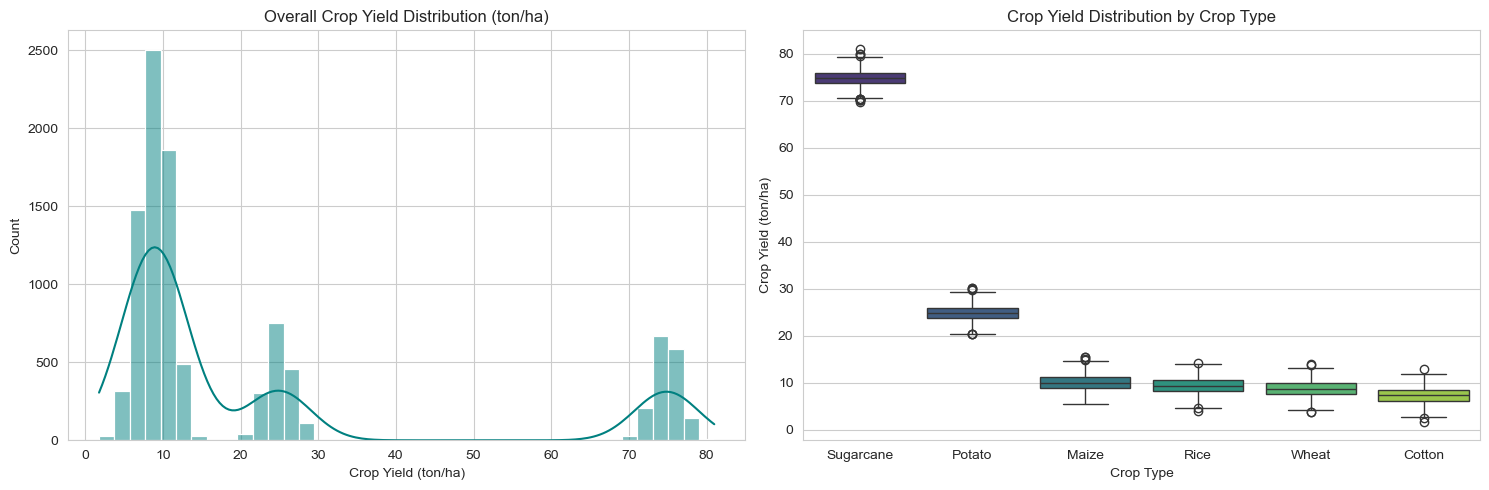

In [19]:
# Summary statistics grouped by Crop_Type
crop_summary = df.groupby('Crop_Type')['Crop_Yield_ton_per_hectare'].agg(
    ['count', 'mean', 'std', 'min', 'median', 'max']
).sort_values(by='mean', ascending=False)
display(crop_summary)

# Plot overall distribution and crop-wise boxplot
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df['Crop_Yield_ton_per_hectare'], bins=40, kde=True, ax=axes[0], color='teal')
axes[0].set_title('Overall Crop Yield Distribution (ton/ha)')
axes[0].set_xlabel('Crop Yield (ton/ha)')

sns.boxplot(
    data=df,
    x='Crop_Type',
    y='Crop_Yield_ton_per_hectare',
    order=crop_summary.index,
    palette='viridis',
    ax=axes[1]
)
axes[1].set_title('Crop Yield Distribution by Crop Type')
axes[1].set_xlabel('Crop Type')
axes[1].set_ylabel('Crop Yield (ton/ha)')

plt.tight_layout()
plt.show()

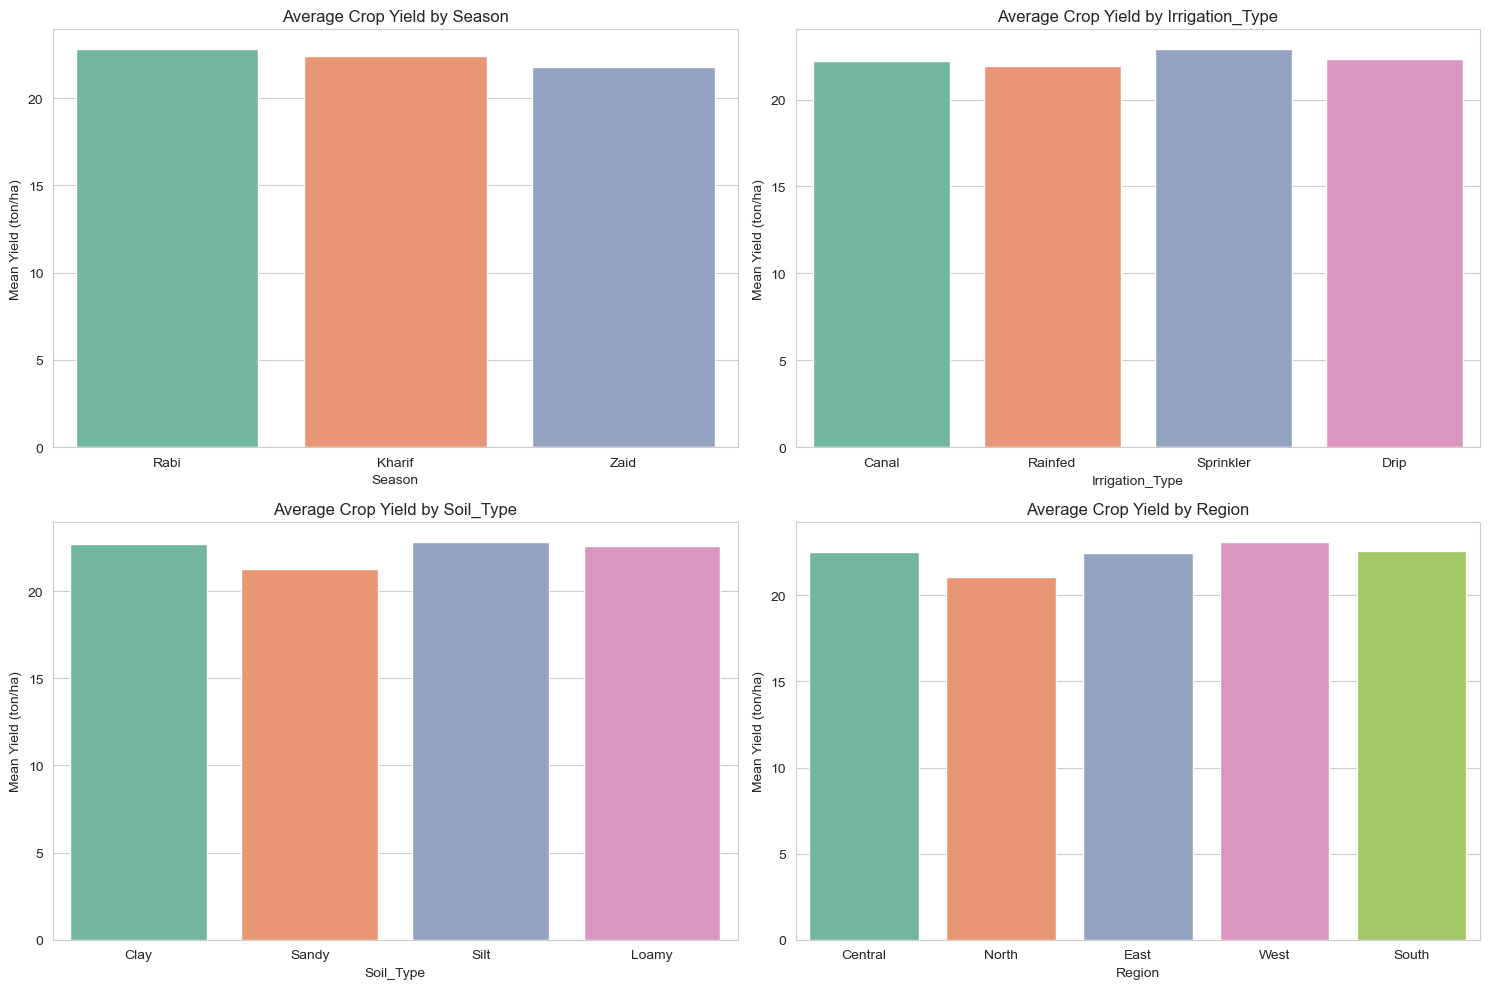

In [21]:
cat_features = ['Season', 'Irrigation_Type', 'Soil_Type', 'Region']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    sns.barplot(
        data=df,
        x=col,
        y='Crop_Yield_ton_per_hectare',
        estimator=np.mean,
        errorbar=None,
        palette='Set2',
        ax=axes[i]
    )
    axes[i].set_title(f'Average Crop Yield by {col}')
    axes[i].set_ylabel('Mean Yield (ton/ha)')
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

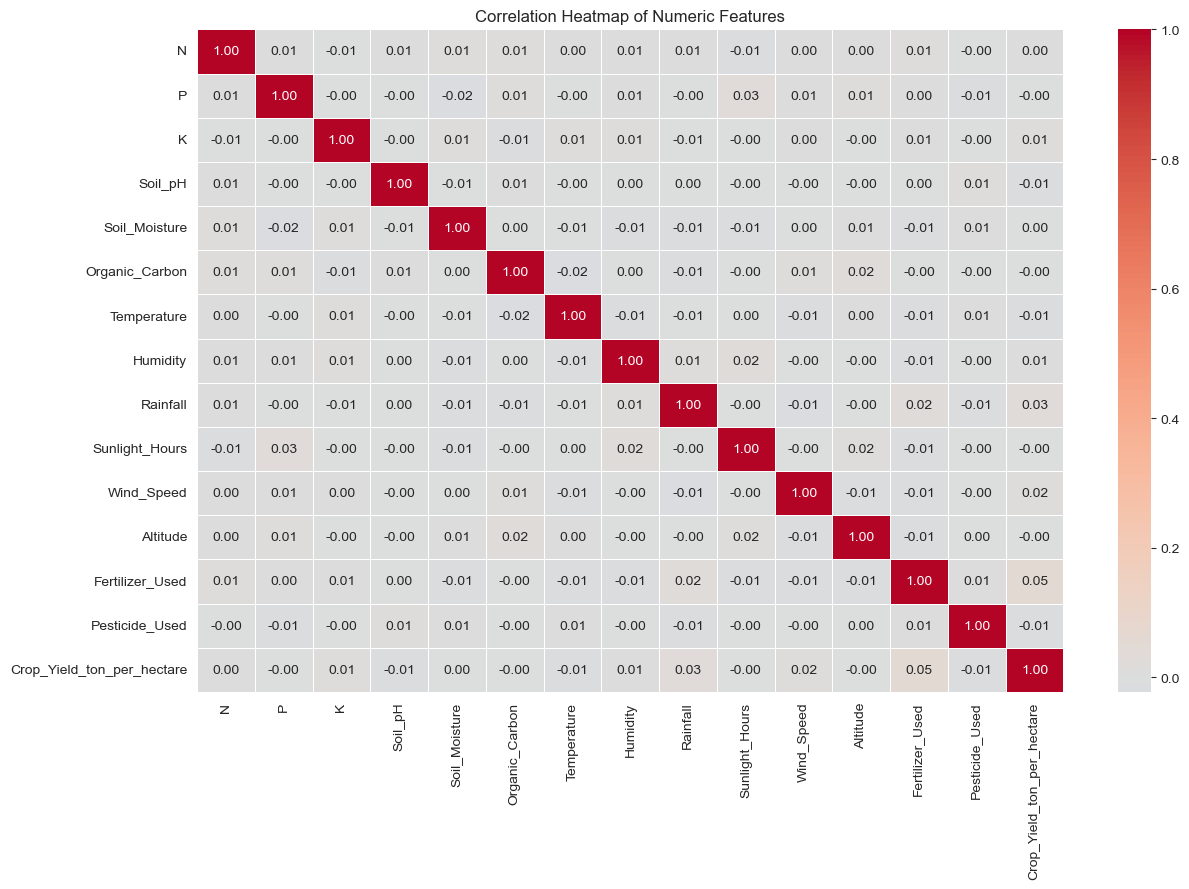

In [23]:
num_cols = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(13, 9))
corr_matrix = df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Features')
plt.tight_layout()
plt.show()

,Maize,Potato,Rice,Sugarcane,Wheat,Cotton
N,0.161,0.138,0.122,0.157,0.137,0.173
P,0.084,0.079,0.059,0.090,0.071,0.105
K,0.114,0.115,0.131,0.165,0.084,0.104
Soil_pH,-0.014,0.011,-0.046,-0.008,0.010,0.011
Soil_Moisture,0.263,0.256,0.220,0.262,0.296,0.233
Organic_Carbon,-0.035,-0.014,0.010,-0.000,0.016,0.009
Temperature,-0.040,-0.045,-0.020,0.013,0.057,-0.017
Humidity,0.022,0.005,0.031,-0.014,-0.018,-0.008
Rainfall,0.475,0.463,0.443,0.417,0.398,0.436
Sunlight_Hours,0.012,-0.000,-0.003,-0.044,0.027,0.009


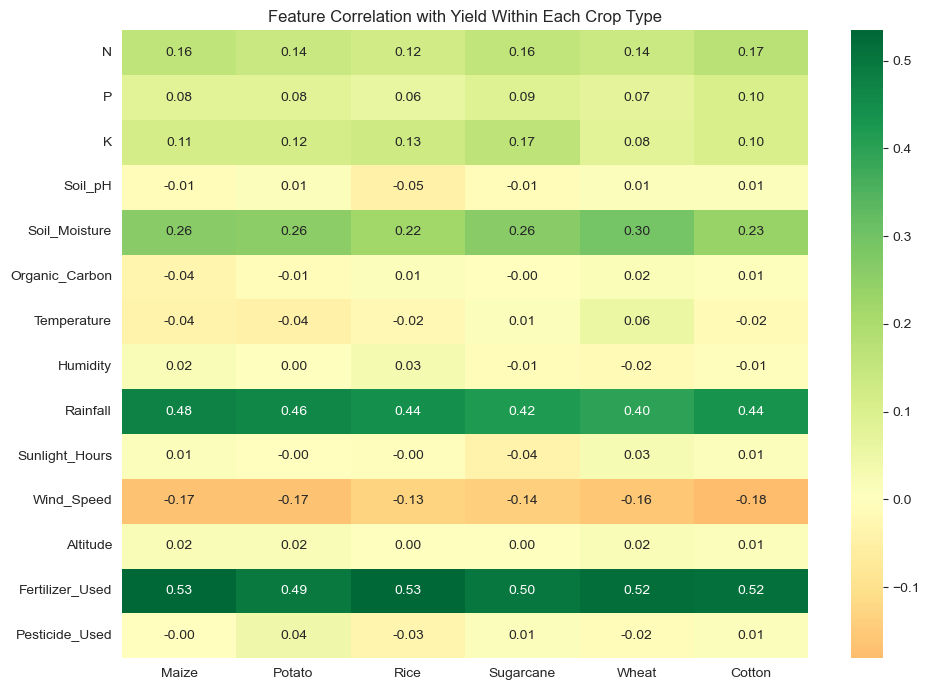

In [25]:
# Compare feature correlations with Yield inside each crop
crop_corrs = {}
for crop in df['Crop_Type'].unique():
    sub = df[df['Crop_Type'] == crop]
    crop_corrs[crop] = sub[num_cols].corr()['Crop_Yield_ton_per_hectare'].drop('Crop_Yield_ton_per_hectare')

crop_corr_df = pd.DataFrame(crop_corrs)
display(crop_corr_df.round(3))

plt.figure(figsize=(10, 7))
sns.heatmap(crop_corr_df, annot=True, fmt='.2f', cmap='RdYlGn', center=0)
plt.title('Feature Correlation with Yield Within Each Crop Type')
plt.tight_layout()
plt.show()

In [32]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=['Crop_Yield_ton_per_hectare'])
y = df['Crop_Yield_ton_per_hectare']

# Identify numeric and categorical feature columns
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print(f"Numeric features ({len(numeric_features)}):", numeric_features)
print(f"Categorical features ({len(categorical_features)}):", categorical_features)

# 80/20 Train-Test Split stratified by Crop_Type
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=X['Crop_Type']
)

print(f"\nX_train shape: {X_train.shape} | X_test shape: {X_test.shape}")

Numeric features (14): ['N', 'P', 'K', 'Soil_pH', 'Soil_Moisture', 'Organic_Carbon', 'Temperature', 'Humidity', 'Rainfall', 'Sunlight_Hours', 'Wind_Speed', 'Altitude', 'Fertilizer_Used', 'Pesticide_Used']
Categorical features (5): ['Soil_Type', 'Region', 'Season', 'Crop_Type', 'Irrigation_Type']

X_train shape: (8000, 19) | X_test shape: (2000, 19)


In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ]
)

# Verify the transformed feature dimensions
X_train_processed = preprocessor.fit_transform(X_train)
print("Transformed X_train shape:", X_train_processed.shape)

Transformed X_train shape: (8000, 31)


In [36]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

def evaluate_model(name, model_pipeline, X_train, y_train, X_test, y_test):
    model_pipeline.fit(X_train, y_train)
    y_pred_train = model_pipeline.predict(X_train)
    y_pred_test = model_pipeline.predict(X_test)
    
    return {
        'Model': name,
        'Train R2': round(r2_score(y_train, y_pred_train), 5),
        'Test R2': round(r2_score(y_test, y_pred_test), 5),
        'Test MAE (ton/ha)': round(mean_absolute_error(y_test, y_pred_test), 4),
        'Test RMSE (ton/ha)': round(np.sqrt(mean_squared_error(y_test, y_pred_test)), 4)
    }

print("Evaluation helper ready!")

Evaluation helper ready!


In [38]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=150, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=150, random_state=42),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42)
}

results = []
trained_pipelines = {}

for name, regressor in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', regressor)
    ])
    metrics = evaluate_model(name, pipe, X_train, y_train, X_test, y_test)
    results.append(metrics)
    trained_pipelines[name] = pipe

results_df = pd.DataFrame(results).sort_values(by='Test RMSE (ton/ha)', ascending=True)
display(results_df)

  File "C:\Anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Anaconda\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Anaconda\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Anaconda\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


,Model,Train R2,Test R2,Test MAE (ton/ha),Test RMSE (ton/ha)
4,HistGradientBoosting,0.99888,0.99809,0.8384,1.0501
3,Gradient Boosting,0.99831,0.99803,0.8520,1.0651
1,Ridge Regression,0.99796,0.99792,0.8799,1.0934
0,Linear Regression,0.99796,0.99792,0.8794,1.0937
2,Random Forest,0.99969,0.99780,0.9020,1.1257


Best Performing Model: HistGradientBoosting


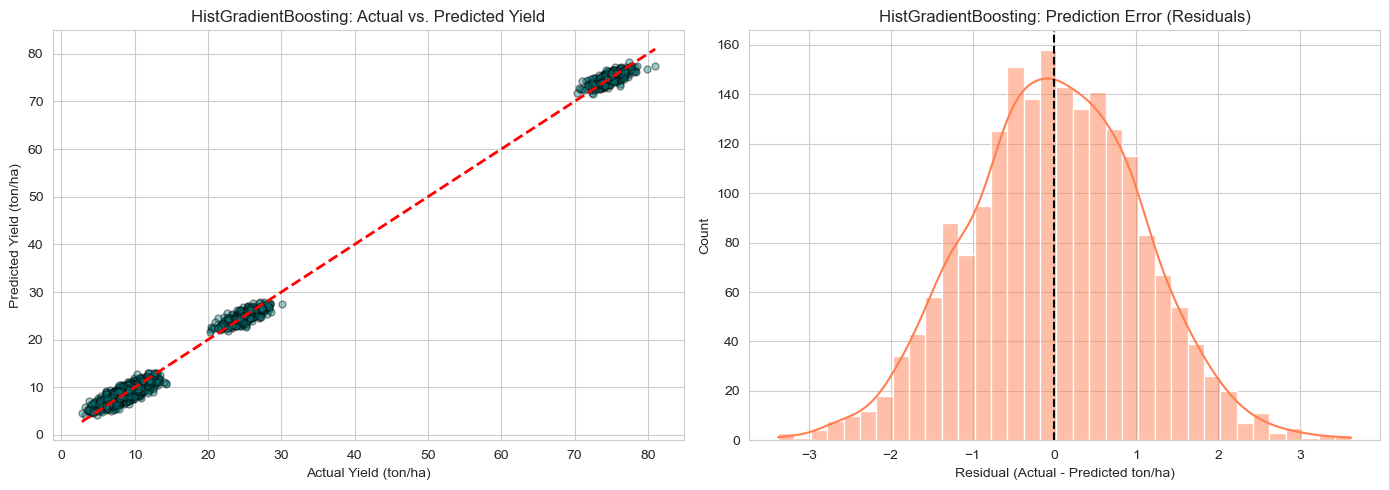

In [40]:
best_model_name = results_df.iloc[0]['Model']
best_pipeline = trained_pipelines[best_model_name]
print(f"Best Performing Model: {best_model_name}")

y_pred = best_pipeline.predict(X_test)
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(y_test, y_pred, alpha=0.4, color='teal', edgecolor='k', s=25)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title(f'{best_model_name}: Actual vs. Predicted Yield')
axes[0].set_xlabel('Actual Yield (ton/ha)')
axes[0].set_ylabel('Predicted Yield (ton/ha)')

# Residual Distribution
sns.histplot(residuals, bins=35, kde=True, ax=axes[1], color='coral')
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set_title(f'{best_model_name}: Prediction Error (Residuals)')
axes[1].set_xlabel('Residual (Actual - Predicted ton/ha)')

plt.tight_layout()
plt.show()

In [42]:
from sklearn.model_selection import cross_val_score

cv_r2 = cross_val_score(best_pipeline, X, y, cv=5, scoring='r2', n_jobs=-1)
cv_mae = -cross_val_score(best_pipeline, X, y, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1)

print(f"5-Fold CV R2:  {cv_r2.mean():.5f} (+/- {cv_r2.std():.5f})")
print(f"5-Fold CV MAE: {cv_mae.mean():.4f} (+/- {cv_mae.std():.4f}) ton/ha")

5-Fold CV R2:  0.99804 (+/- 0.00006)
5-Fold CV MAE: 0.8533 (+/- 0.0069) ton/ha


In [46]:
# Load the saved pipeline from disk
loaded_pipeline = joblib.load('crop_yield_pipeline.pkl')
loaded_meta = joblib.load('crop_yield_metadata.pkl')

# Sample user input (as received from a web form or API request)
sample_input = {
    'N': 110,
    'P': 60,
    'K': 85,
    'Soil_pH': 6.5,
    'Soil_Moisture': 42.0,
    'Soil_Type': 'Loamy',
    'Organic_Carbon': 0.95,
    'Temperature': 26.5,
    'Humidity': 65.0,
    'Rainfall': 1450.0,
    'Sunlight_Hours': 8.0,
    'Wind_Speed': 9.0,
    'Region': 'South',
    'Altitude': 600,
    'Season': 'Kharif',
    'Crop_Type': 'Rice',
    'Irrigation_Type': 'Canal',
    'Fertilizer_Used': 210.0,
    'Pesticide_Used': 12.0
}

# Convert single dict to DataFrame in exact column order and predict
input_df = pd.DataFrame([sample_input])[loaded_meta['feature_columns']]
predicted_yield = loaded_pipeline.predict(input_df)[0]

print(f"Predicted Yield for {sample_input['Crop_Type']}: {predicted_yield:.2f} ton/hectare")

Predicted Yield for Rice: 9.98 ton/hectare


In [48]:
test_crops = ['Rice', 'Wheat', 'Maize', 'Cotton', 'Potato', 'Sugarcane']

print("--- Sample Predictions Across All 6 Crops (Same Soil/Weather Inputs) ---")
for crop in test_crops:
    row = sample_input.copy()
    row['Crop_Type'] = crop
    pred = loaded_pipeline.predict(pd.DataFrame([row])[loaded_meta['feature_columns']])[0]
    print(f"{crop:12s} -> {pred:6.2f} ton/hectare")

--- Sample Predictions Across All 6 Crops (Same Soil/Weather Inputs) ---
Rice         ->   9.98 ton/hectare
Wheat        ->   9.42 ton/hectare
Maize        ->  10.72 ton/hectare
Cotton       ->   7.95 ton/hectare
Potato       ->  25.84 ton/hectare
Sugarcane    ->  75.20 ton/hectare


Removing few inputs to increase accuracy (This reduses fitting random noise)

,Feature,MAE_Increase
15,Crop_Type,20.778530
17,Fertilizer_Used,0.532887
9,Rainfall,0.418066
4,Soil_Moisture,0.183300
3,Soil_pH,0.161480
11,Wind_Speed,0.083093
0,N,0.063136
2,K,0.057080
1,P,0.035490
8,Humidity,0.011870


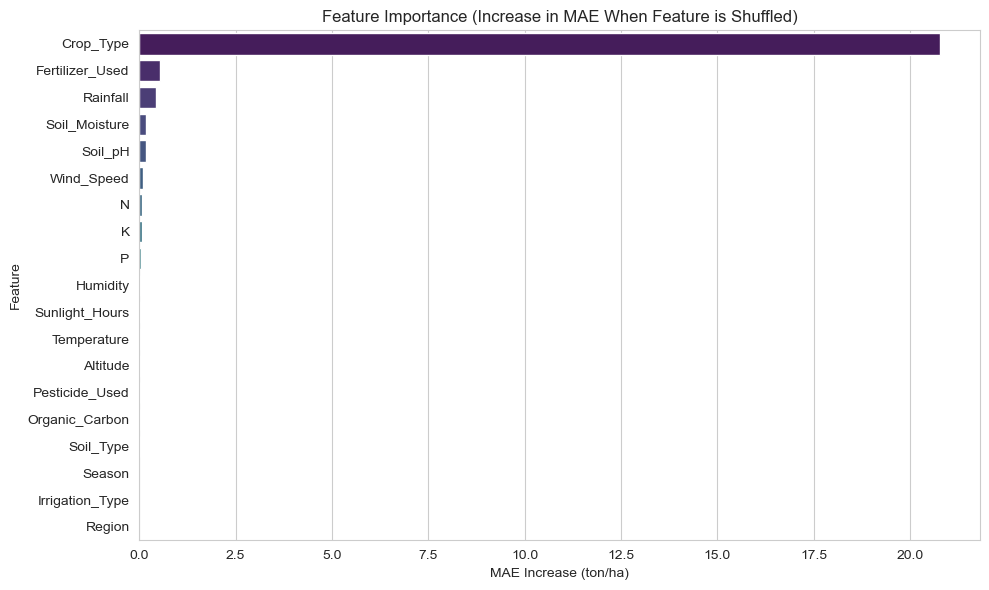

Selected 9 features: ['Crop_Type', 'N', 'P', 'K', 'Soil_pH', 'Soil_Moisture', 'Rainfall', 'Wind_Speed', 'Fertilizer_Used']


In [50]:

from sklearn.inspection import permutation_importance

# Compute permutation importance on the full 19-feature model
perm = permutation_importance(
    trained_pipelines[best_model_name],
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'MAE_Increase': perm.importances_mean
}).sort_values(by='MAE_Increase', ascending=False)

display(importance_df)

# Visualize feature importance
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x='MAE_Increase', y='Feature', palette='viridis')
plt.title('Feature Importance (Increase in MAE When Feature is Shuffled)')
plt.xlabel('MAE Increase (ton/ha)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# Select the Top 9 features (Option A)
selected_features = [
    'Crop_Type',
    'N',
    'P',
    'K',
    'Soil_pH',
    'Soil_Moisture',
    'Rainfall',
    'Wind_Speed',
    'Fertilizer_Used'
]

print(f"Selected {len(selected_features)} features:", selected_features)

In [52]:
X_selected = df[selected_features]
y = df['Crop_Yield_ton_per_hectare']

num_selected = [c for c in selected_features if df[c].dtype != 'object']
cat_selected = [c for c in selected_features if df[c].dtype == 'object']

X_train_sel, X_test_sel, y_train_sel, y_test_sel = train_test_split(
    X_selected, y, test_size=0.2, random_state=42, stratify=X_selected['Crop_Type']
)

preprocessor_9 = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_selected),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_selected)
    ]
)

pipeline_9 = Pipeline(steps=[
    ('preprocessor', preprocessor_9),
    ('model', HistGradientBoostingRegressor(random_state=42))
])

# Evaluate on hold-out test set & 5-fold CV
metrics_9 = evaluate_model('HistGradientBoosting (9 Features)', pipeline_9, X_train_sel, y_train_sel, X_test_sel, y_test_sel)
display(pd.DataFrame([metrics_9]))

cv_r2_9 = cross_val_score(pipeline_9, X_selected, y, cv=5, scoring='r2', n_jobs=-1)
cv_mae_9 = -cross_val_score(pipeline_9, X_selected, y, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1)

print(f"5-Fold CV R2 (9 features):  {cv_r2_9.mean():.5f} (+/- {cv_r2_9.std():.5f})")
print(f"5-Fold CV MAE (9 features): {cv_mae_9.mean():.4f} (+/- {cv_mae_9.std():.4f}) ton/ha")

,Model,Train R2,Test R2,Test MAE (ton/ha),Test RMSE (ton/ha)
0,HistGradientBoosting (9 Features),0.9988,0.99809,0.8361,1.0475


5-Fold CV R2 (9 features):  0.99805 (+/- 0.00006)
5-Fold CV MAE (9 features): 0.8503 (+/- 0.0075) ton/ha


In [54]:
# Fit streamlined pipeline on all 10,000 rows
pipeline_9.fit(X_selected, y)

# Save updated pipeline and metadata
joblib.dump(pipeline_9, 'crop_yield_pipeline.pkl')

metadata_9 = {
    'model_name': 'HistGradientBoostingRegressor',
    'feature_columns': selected_features,
    'numeric_features': num_selected,
    'categorical_features': cat_selected,
    'categorical_options': {col: sorted(df[col].unique().tolist()) for col in cat_selected},
    'numeric_ranges': {
        col: {
            'min': float(df[col].min()),
            'max': float(df[col].max()),
            'mean': round(float(df[col].mean()), 2)
        }
        for col in num_selected
    },
    'metrics': {
        'test_r2': metrics_9['Test R2'],
        'test_mae': metrics_9['Test MAE (ton/ha)'],
        'cv_r2': round(float(cv_r2_9.mean()), 5),
        'cv_mae': round(float(cv_mae_9.mean()), 4)
    }
}
joblib.dump(metadata_9, 'crop_yield_metadata.pkl')

print("Updated files saved successfully:")
print("- crop_yield_pipeline.pkl (9 inputs)")
print("- crop_yield_metadata.pkl")

Updated files saved successfully:
- crop_yield_pipeline.pkl (9 inputs)
- crop_yield_metadata.pkl


In [56]:
loaded_pipe = joblib.load('crop_yield_pipeline.pkl')
loaded_meta = joblib.load('crop_yield_metadata.pkl')

sample_9 = {
    'Crop_Type': 'Rice',
    'N': 110,
    'P': 60,
    'K': 85,
    'Soil_pH': 6.5,
    'Soil_Moisture': 42.0,
    'Rainfall': 1450.0,
    'Wind_Speed': 9.0,
    'Fertilizer_Used': 210.0
}

input_df = pd.DataFrame([sample_9])[loaded_meta['feature_columns']]
pred = loaded_pipe.predict(input_df)[0]

print("Required Frontend Inputs:", loaded_meta['feature_columns'])
print(f"Predicted Yield for {sample_9['Crop_Type']}: {pred:.2f} ton/hectare")

Required Frontend Inputs: ['Crop_Type', 'N', 'P', 'K', 'Soil_pH', 'Soil_Moisture', 'Rainfall', 'Wind_Speed', 'Fertilizer_Used']
Predicted Yield for Rice: 10.12 ton/hectare


In [58]:
import joblib
import pandas as pd

loaded_pipe = joblib.load('crop_yield_pipeline.pkl')
loaded_meta = joblib.load('crop_yield_metadata.pkl')

test_cases = [
    {'Crop_Type': 'Sugarcane', 'N': 140, 'P': 80, 'K': 120, 'Soil_pH': 6.8, 'Soil_Moisture': 52.0, 'Rainfall': 2100.0, 'Wind_Speed': 7.5, 'Fertilizer_Used': 290.0},
    {'Crop_Type': 'Potato',    'N': 125, 'P': 70, 'K': 110, 'Soil_pH': 6.0, 'Soil_Moisture': 45.0, 'Rainfall': 1600.0, 'Wind_Speed': 8.0, 'Fertilizer_Used': 240.0},
    {'Crop_Type': 'Maize',     'N': 100, 'P': 55, 'K': 80,  'Soil_pH': 6.4, 'Soil_Moisture': 38.0, 'Rainfall': 1300.0, 'Wind_Speed': 10.0, 'Fertilizer_Used': 190.0},
    {'Crop_Type': 'Wheat',     'N': 95,  'P': 50, 'K': 75,  'Soil_pH': 6.7, 'Soil_Moisture': 35.0, 'Rainfall': 1100.0, 'Wind_Speed': 9.5, 'Fertilizer_Used': 180.0},
    {'Crop_Type': 'Cotton',    'N': 70,  'P': 35, 'K': 50,  'Soil_pH': 7.2, 'Soil_Moisture': 24.0, 'Rainfall': 750.0,  'Wind_Speed': 14.0, 'Fertilizer_Used': 110.0}
]

input_df = pd.DataFrame(test_cases)[loaded_meta['feature_columns']]
predictions = loaded_pipe.predict(input_df)

for case, pred in zip(test_cases, predictions):
    print(f"{case['Crop_Type']:10s} -> {pred:.2f} ton/hectare")

Sugarcane  -> 77.41 ton/hectare
Potato     -> 26.62 ton/hectare
Maize      -> 10.24 ton/hectare
Wheat      -> 8.61 ton/hectare
Cotton     -> 4.74 ton/hectare
